In [22]:
import numpy as np

# Fungsi aktivasi
def sigmoid(x):
 return 1 / (1 + np.exp(-x))

def tanh(x):
 return np.tanh(x)

# Data deret waktu
X = [0.2, 0.5, 0.8, 0.1, 0.4]

# Inisialisasi bobot (disederhanakan menjadi skalar agar mudah dibaca)
# Bobot untuk input (W), hidden state sebelumnya (U), dan bias (b)
W_f, U_f, b_f = 0.5, 0.4, -0.1  # Forget gate
W_i, U_i, b_i = 0.6, 0.5, 0.0   # Input gate
W_c, U_c, b_c = 0.7, 0.6, 0.1   # Cell candidate
W_o, U_o, b_o = 0.8, 0.7, 0.2   # Output gate

# Status awal (memori kosong)
h_t = 0.0
C_t = 0.0  # Menggunakan C_t kapital

print("=== Simulasi Evolusi Memori LSTM ===")
for t, x_t in enumerate(X):
    print(f"\n--- Langkah Waktu t{t+1} (Input x={x_t}) ---")

    # 1. Forget gate (menentukan informasi lama yang dibuang)
    f_t = sigmoid(W_f * x_t + U_f * h_t + b_f)

    # 2. Input Gate & Candidate (menentukan informasi baru)
    i_t = sigmoid(W_i * x_t + U_i * h_t + b_i)
    C_cand = tanh(W_c * x_t + U_c * h_t + b_c)

    # 3. Update cell state (memori jangka panjang)
    # Diperbaiki: c_t kecil diubah menjadi C_t besar agar sesuai dengan inisialisasi awal
    C_t = (f_t * C_t) + (i_t * C_cand)

    # 4. Output Gate & Hidden State
    o_t = sigmoid(W_o * x_t + U_o * h_t + b_o)
    h_t = o_t * tanh(C_t)

    print(f"forget gate (f_t) : {f_t:.4f} -> {f_t*100:.1f}% memori lama dipertahankan")
    print(f"Input Gate (i_t) : {i_t:.4f} -> {i_t*100:.1f}% informasi baru dimasukan")
    print(f"Cell State (C_t) : {C_t:.4f} -> {C_t*100:.1f}% informasi jangka panjang")
    print(f"Hidden State (h_t): {h_t:.4f} (output saat ini)")

=== Simulasi Evolusi Memori LSTM ===

--- Langkah Waktu t1 (Input x=0.2) ---
forget gate (f_t) : 0.5000 -> 50.0% memori lama dipertahankan
Input Gate (i_t) : 0.5300 -> 53.0% informasi baru dimasukan
Cell State (C_t) : 0.1248 -> 12.5% informasi jangka panjang
Hidden State (h_t): 0.0731 (output saat ini)

--- Langkah Waktu t2 (Input x=0.5) ---
forget gate (f_t) : 0.5447 -> 54.5% memori lama dipertahankan
Input Gate (i_t) : 0.5834 -> 58.3% informasi baru dimasukan
Cell State (C_t) : 0.3347 -> 33.5% informasi jangka panjang
Hidden State (h_t): 0.2122 (output saat ini)

--- Langkah Waktu t3 (Input x=0.8) ---
forget gate (f_t) : 0.5950 -> 59.5% memori lama dipertahankan
Input Gate (i_t) : 0.6425 -> 64.2% informasi baru dimasukan
Cell State (C_t) : 0.6212 -> 62.1% informasi jangka panjang
Hidden State (h_t): 0.4023 (output saat ini)

--- Langkah Waktu t4 (Input x=0.1) ---
forget gate (f_t) : 0.5277 -> 52.8% memori lama dipertahankan
Input Gate (i_t) : 0.5649 -> 56.5% informasi baru dimasukan


In [23]:
W_xh = 0.6
W_hh = 0.5
b_h = 0.1

#Status Awal
h_t_rnn = 0.0

print("=== Simulasi Evolusi Memori RNN Biasa ===")
for t, x_t in enumerate(X):
    print(f"\n--- Langkah waktu t={t+1} (Input x={x_t})---")

    #Update Hidden State Tunggal Pada RNN
    h_t_rnn = tanh(W_hh * h_t_rnn + W_xh * x_t + b_h)

    print(f"Hidden State (h_t): {h_t_rnn:.4f}")

=== Simulasi Evolusi Memori RNN Biasa ===

--- Langkah waktu t=1 (Input x=0.2)---
Hidden State (h_t): 0.2165

--- Langkah waktu t=2 (Input x=0.5)---
Hidden State (h_t): 0.4686

--- Langkah waktu t=3 (Input x=0.8)---
Hidden State (h_t): 0.6720

--- Langkah waktu t=4 (Input x=0.1)---
Hidden State (h_t): 0.4589

--- Langkah waktu t=5 (Input x=0.4)---
Hidden State (h_t): 0.5150


/tmp/ipykernel_744/1812933501.py:18: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  return torch.tensor(xs, dtype=torch.float32).unsqueeze(-1), torch.tensor(ys, dtype=torch.float32).unsqueeze(-1)


=== Melatih Model LSTM ===
Epoch: 10/50 - Loss LSTM: 0.1639
Epoch: 20/50 - Loss LSTM: 0.0212
Epoch: 30/50 - Loss LSTM: 0.0176
Epoch: 40/50 - Loss LSTM: 0.0173
Epoch: 50/50 - Loss LSTM: 0.0166


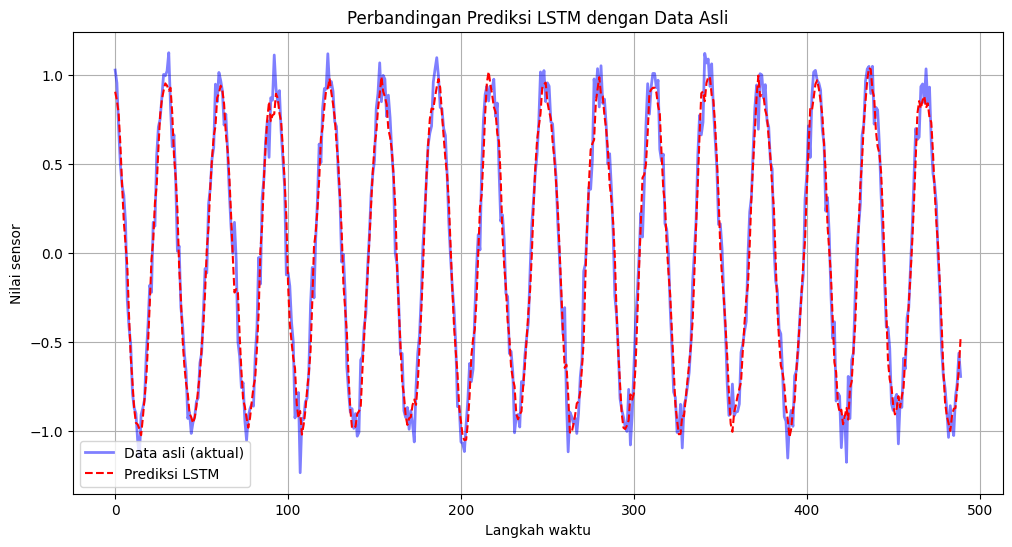

In [26]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np

# 1. Menyiapkan Data Deret Waktu (Sine Wave + Noise)
time_steps = np.linspace(0, 100, 500)
data = np.sin(time_steps) + np.random.normal(0, 0.1, 500)

def create_sequences(data, seq_length):
    xs, ys = [], []
    for i in range(len(data) - seq_length):
        xs.append(data[i:(i + seq_length)])
        ys.append(data[i + seq_length])
    # Perbaikan: 'return' dipindah ke luar loop agar seluruh data terproses,
    # 'float23' diperbaiki ke 'float32', dan 'torch.sensor' diperbaiki ke 'torch.tensor'
    return torch.tensor(xs, dtype=torch.float32).unsqueeze(-1), torch.tensor(ys, dtype=torch.float32).unsqueeze(-1)

seq_length = 10
X_seq, y_seq = create_sequences(data, seq_length)

# 2. Definisi Arsitektur Model LSTM
class ModelLSTM(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()  # Perbaikan: _init__ menjadi __init__
        self.lstm = nn.LSTM(input_size, hidden_size, batch_first=True) # Perbaikan: nn,LSTM menjadi nn.LSTM
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):  # Perbaikan: foward menjadi forward, indentasi dirapikan
        lstm_out, (hn, cn) = self.lstm(x)  # Perbaikan: lstm.out menjadi lstm_out
        pred = self.fc(lstm_out[:, -1, :]) # Perbaikan: self.linear menjadi self.fc
        return pred


input_size = 1
hidden_size = 32
output_size = 1

model_lstm = ModelLSTM(input_size, hidden_size, output_size) # Mengisi argumen inisialisasi
criterion = nn.MSELoss()
optimizer = optim.Adam(model_lstm.parameters(), lr=0.01) # Perbaikan: optimal menjadi optim


print("=== Melatih Model LSTM ===")
epochs = 50
for epoch in range(epochs):
    optimizer.zero_grad()
    y_pred_lstm = model_lstm(X_seq)
    loss_lstm = criterion(y_pred_lstm, y_seq)
    loss_lstm.backward()
    optimizer.step()


    if (epoch + 1) % 10 == 0:
        print(f"Epoch: {epoch+1}/{epochs} - Loss LSTM: {loss_lstm.item():.4f}")

# 4. Visualisasi Hasil Prediksi
plt.figure(figsize=(12, 6))
plt.plot(y_seq.numpy(), label='Data asli (aktual)', color='blue', alpha=0.5, linewidth=2)
plt.plot(y_pred_lstm.detach().numpy(), label='Prediksi LSTM', color='red', linestyle='dashed')
plt.title('Perbandingan Prediksi LSTM dengan Data Asli')
plt.xlabel('Langkah waktu')
plt.ylabel('Nilai sensor')
plt.legend()
plt.grid(True)
plt.show()